# Análise Epidemiológica e Distribuição de Medicamentos na Farmácia Básica

**Projeto:** Gestão da Assistência Farmacêutica

**Autoras:** Beatriz Goulart e Esther de Oliveira  

**Arquivo de Origem:** `dispensacao_analitico.csv`  

---

## Contexto e Objetivos
A nomenclatura técnica de medicamentos (princípios ativos) em bases analíticas dificulta a interpretação gestora e o acesso público à informação.

Esta análise categoriza os registros de dispensação em **Perfis de Cuidado e Tratamento** funcionais (ex.: *Saúde Cardiovascular*, *Controle Metabólico*, *Infectologia*), visando:
1. Mapear as linhas de cuidado com maior demanda de suprimentos.
2. Identificar a distribuição de dispensação entre os estabelecimentos de saúde.
3. Garantir transparência sobre o volume de itens não categorizados (`Outros / Não Classificado`).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

file_path = "../../data/processed/dispensacao_analitico.csv"

try:
    df = pd.read_csv(file_path)
    print(f"Base carregada com sucesso: {df.shape[0]} registros e {df.shape[1]} colunas.")
    print("\nColunas encontradas na base:")
    print(df.columns.tolist())
except FileNotFoundError:
    print(f"Arquivo não encontrado em {file_path}. Verifique o caminho dos dados.")

Base carregada com sucesso: 220815 registros e 25 colunas.

Colunas encontradas na base:
['competencia_inicial', 'competencia_final', 'ups_nome', 'ups_codigo', 'bairro_nome', 'bairro_codigo', 'centro_custo_nome', 'centro_custo_codigo', 'material_nome', 'material_nome_base', 'material_descricao_complementar', 'material_tipo', 'classe_terapeutica', 'tipo_tratamento', 'material_codigo', 'data', 'saida', 'usuario', 'fabricante_codigo', 'fabricante_nome', 'lote', 'numero_receita', 'validade', 'quantidade', 'custo_medio']


### 1. Metodologia: Classificação por Perfil de Cuidado
Para transformar os registros brutos em uma visão voltada para a gestão em saúde, a base foi agrupada em **eixos terapêuticos e perfis de cuidado** (como hipertensão, diabetes, saúde mental, entre outros). 

* **Tratamento de exceção:** Registros que não se encaixam nos principais eixos de atenção básica foram mantidos visíveis na categoria **"Outros / Não Classificados"**, garantindo a transparência total do volume de dispensações do município e evitando distorções na leitura dos dados.

In [25]:
if 'material_nome' in df.columns:
    df['nome_completo_med'] = (
        df['material_nome'].fillna('').astype(str) + ' ' + 
        df['material_descricao_complementar'].fillna('').astype(str)
    ).str.strip()
    coluna_med = 'nome_completo_med'
else:
    coluna_med = [col for col in df.columns if any(k in col.upper() for k in ['MEDICAMENTO', 'PRODUTO', 'DESCRICAO'])][0]

mapeamento_cuidados = {
    "Cardiovascular / Hipertensão": [
        "LOSARTANA", "ENALAPRIL", "ATENOLOL", "HIDROCLOROTIAZIDA", 
        "ANLODIPINO", "CAPTOPRIL", "SINVASTATINA", "PROPRANOLOL", 
        "FUROSEMIDA", "ESPIRONOLACTONA", "CARVEDILOL",
        "ACIDO ACETILSALICILICO", "CLOPIDOGREL", "METOPROLOL",
        "ISOSSORBIDA" 
    ],
    "Controle de Diabetes": [
        "METFORMINA", "GLIBENCLAMIDA", "INSULINA", "GLICLAZIDA", "CANETA INSULINA"
    ],
    "Saúde Mental / Psicotrópicos": [
        "FLUOXETINA", "SERTRALINA", "AMITRIPTILINA", "CLONAZEPAM", 
        "DIAZEPAM", "HALOPERIDOL", "RISPERIDONA", "CARBONATO DE LITIO",
        "VALPROATO", "CARBAMAZEPINA", "CLORPROMAZINA",
        "ACIDO VALPROICO", "NORTRIPTILINA"
    ],
    "Dor e Inflamação": [
        "DIPIRONA", "PARACETAMOL", "IBUPROFENO", "DICLOFENACO", "TRAMADOL", 
        "PREDNISONA", "PREDNISOLONA"
    ],
    "Anti-infecciosos / Antibióticos": [
        "AMOXICILINA", "AZITROMICINA", "CEFALEXINA", "CIPROFLOXACINO", 
        "SULFAMETOXAZOL", "NITROFURANTOINA", "METRONIDAZOL" 
    ],
    "Saúde Respiratória e Alergias": [ 
        "SALBUTAMOL", "BECLOMETASONA", "BUDESONIDA", "IPRATROPIO", "LORATADINA"
    ],
    "Gastrointestinal": [
        "OMEPRAZOL", "HIDROXIDO DE ALUMINIO", "RANITIDINA", "METOCLOPRAMIDA"
    ],
    "Saúde Endócrina e Metabólica": [
        "LEVOTIROXINA", "CARBONATO DE CALCIO", "CALCIO"
    ],
    "Saúde Nutricional e Suplementos": [
        "SULFATO FERROSO", "POLIVITAMINICO"
    ],
    "Saúde Urológica e Outros Crônicos": [
        "FINASTERIDA", "ALENDRONATO", "DOXAZOSINA"
    ]
}

def normalizar_texto(txt):
    if not isinstance(txt, str):
        return ""
    return unicodedata.normalize('NFKD', txt).encode('ASCII', 'ignore').decode('ASCII').upper()

def classificar_medicamento(nome_medicamento):
    nome_norm = normalizar_texto(nome_medicamento)
    if not nome_norm:
        return "Outros / Não Classificados"
    for perfil, termos in mapeamento_cuidados.items():
        for termo in termos:
            if termo in nome_norm:
                return perfil
    return "Outros / Não Classificados"

df['perfil_cuidado'] = df[coluna_med].apply(classificar_medicamento)

### 2. Distribuição dos Perfis de Cuidado
O volume total dispensado evidencia o peso relativo de cada eixo terapêutico dentro da rede municipal. A visualização abaixo demonstra quais linhas de atendimento concentram a maior carga de dispensação de medicamentos para a população:

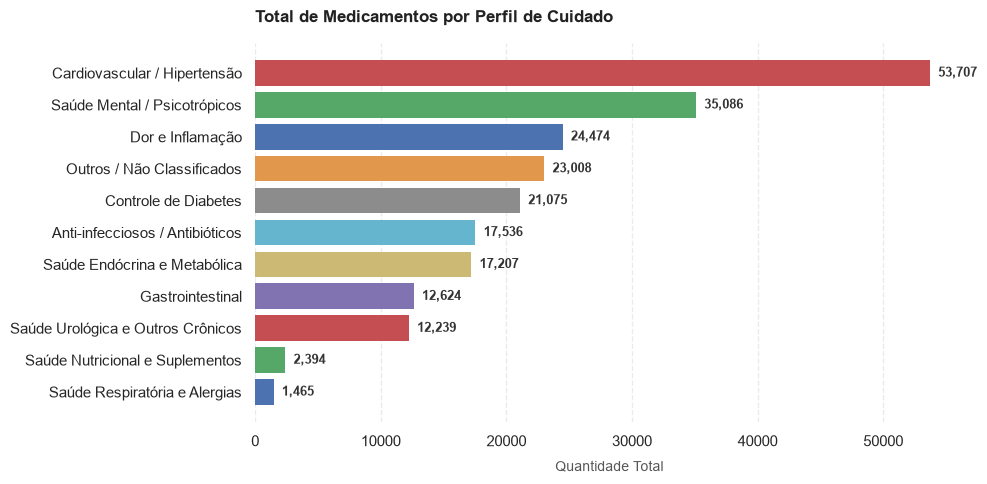

,Perfil de Cuidado,Total de Dispensações
10,Saúde Respiratória e Alergias,1465
9,Saúde Nutricional e Suplementos,2394
8,Saúde Urológica e Outros Crônicos,12239
7,Gastrointestinal,12624
6,Saúde Endócrina e Metabólica,17207
5,Anti-infecciosos / Antibióticos,17536
4,Controle de Diabetes,21075
3,Outros / Não Classificados,23008
2,Dor e Inflamação,24474
1,Saúde Mental / Psicotrópicos,35086


In [26]:
if 'perfil_cuidado' not in df.columns:
    print("Erro: A coluna 'perfil_cuidado' ainda não existe. Rode a célula de classificação dos medicamentos primeiro!")
else:
    contagem_perfis = df['perfil_cuidado'].value_counts().reset_index()
    contagem_perfis.columns = ['Perfil de Cuidado', 'Total de Dispensações']

    contagem_perfis = contagem_perfis.sort_values(by='Total de Dispensações', ascending=True)

    fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

    cores = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD', '#8C8C8C', '#E1974C']

    ax.barh(
        contagem_perfis['Perfil de Cuidado'], 
        contagem_perfis['Total de Dispensações'], 
        color=cores[:len(contagem_perfis)],
        edgecolor='none'
    )

    sns.despine(left=True, bottom=True)
    ax.xaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
    ax.yaxis.grid(False)

    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width):,}',
                xy=(width, p.get_y() + p.get_height() / 2),
                xytext=(6, 0),
                textcoords='offset points',
                ha='left',
                va='center',
                fontsize=9,
                fontweight='bold',
                color='#333333'
            )

    plt.title('Total de Medicamentos por Perfil de Cuidado', fontsize=12, fontweight='bold', pad=15, loc='left', color='#222222')
    plt.xlabel('Quantidade Total', fontsize=10, labelpad=8, color='#555555')
    plt.ylabel('', fontsize=10)

    plt.tight_layout()
    plt.show()

    display(contagem_perfis)

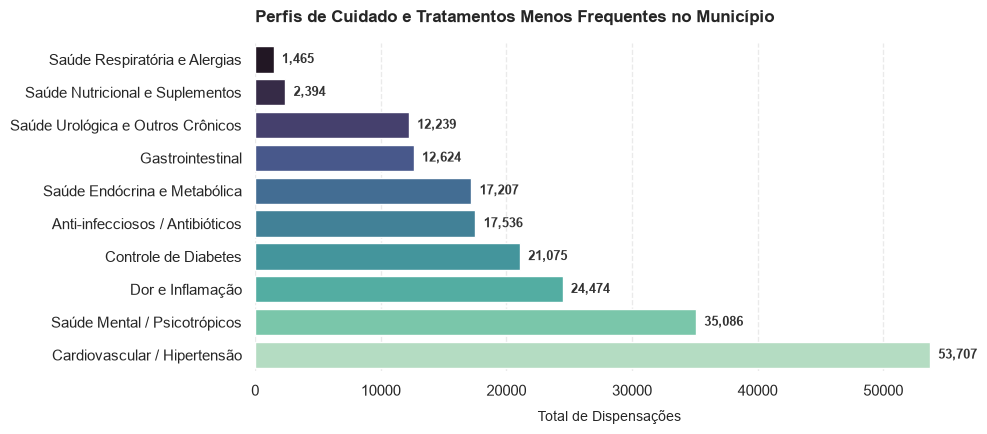

,Perfil de Cuidado,Total de Dispensações
10,Saúde Respiratória e Alergias,1465
9,Saúde Nutricional e Suplementos,2394
8,Saúde Urológica e Outros Crônicos,12239
7,Gastrointestinal,12624
6,Saúde Endócrina e Metabólica,17207
5,Anti-infecciosos / Antibióticos,17536
4,Controle de Diabetes,21075
2,Dor e Inflamação,24474
1,Saúde Mental / Psicotrópicos,35086
0,Cardiovascular / Hipertensão,53707


In [29]:
contagem_perfis = df['perfil_cuidado'].value_counts().reset_index()
contagem_perfis.columns = ['Perfil de Cuidado', 'Total de Dispensações']

perfis_raros = contagem_perfis[
    ~contagem_perfis['Perfil de Cuidado'].isin(['Outros / Não Classificados', 'Outros'])
].copy()

perfis_raros = perfis_raros.sort_values(by='Total de Dispensações', ascending=True)

plt.figure(figsize=(10, 4.5), dpi=100)

ax = sns.barplot(
    data=perfis_raros,
    x='Total de Dispensações',
    y='Perfil de Cuidado',
    palette='mako',
    hue='Perfil de Cuidado',
    legend=False
)

sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.yaxis.grid(False)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f'{int(width):,}',
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(6, 0),
            textcoords='offset points',
            ha='left',
            va='center',
            fontsize=9,
            fontweight='bold',
            color='#333333'
        )

plt.title('Perfis de Cuidado e Tratamentos Menos Frequentes no Município', fontsize=12, fontweight='bold', pad=15, loc='left')
plt.xlabel('Total de Dispensações', fontsize=10, labelpad=8)
plt.ylabel('')
plt.tight_layout()
plt.show()

display(perfis_raros)

### Discussão sobre os perfis de menor frequência
A análise evidencia perfis de cuidado com menor volume de dispensação na rede municipal. A existência desses tratamentos menos frequentes justifica-se por fatores como:

* **Sazonalidade e Demandas Específicas:** Grupos como **Saúde Respiratória e Alergias** e **Saúde Nutricional e Suplementos** apresentam menor fluxo contínuo porque respondem a quadros sazonais ou reposições específicas de menor escala, diferindo do uso diário massivo exigido por patologias crônicas de grande abrangência (como hipertensão e saúde mental).
* **Abrangência e Assistência Abrangente:** A presença desses perfis na Farmácia Básica demonstra que a rede pública cumpre o papel de suprir demandas terapêuticas pontuais da população, garantindo a integralidade do cuidado para além dos grandes programas de crônicos.

### 3. Composição dos Medicamentos por Perfil de Cuidado
Abaixo estão detalhados os 5 principais princípios ativos e insumos mais dispensados dentro de cada eixo terapêutico. Esse detalhamento permite verificar quais apresentações e concentrações puxam o volume de cada categoria.

In [6]:
top_medicamentos = (
    df.groupby(['perfil_cuidado', coluna_med])
    .size()
    .reset_index(name='contagem')
    .sort_values(['perfil_cuidado', 'contagem'], ascending=[True, False])
    .groupby('perfil_cuidado')
    .head(5)
)

display(top_medicamentos)

,perfil_cuidado,nome_completo_med,contagem
3,Anti-infecciosos / Antibióticos,AMOXICILINA+CLAVULANATO - 500/125MG - COMPRIMI...,4399
1,Anti-infecciosos / Antibióticos,AMOXICILINA - AMOXICILINA - 500 MG - COMPRIMID...,2590
5,Anti-infecciosos / Antibióticos,AZITROMICINA - AZITROMICINA 500 MG COMPRIMIDO ...,2403
7,Anti-infecciosos / Antibióticos,CEFALEXINA - 500MG - COMPRIMIDO 500MG,1783
8,Anti-infecciosos / Antibióticos,CIPROFLOXACINO - 500MG - COMPRIMIDO 500MG,1177
14,Cardiovascular / Hipertensão,ACIDO ACETILSALICILICO - 100MG - COMPRIMIDO 100MG,11334
33,Cardiovascular / Hipertensão,SINVASTATINA - 20MG - COMPRIMIDO 20MG,7537
22,Cardiovascular / Hipertensão,CLOPIDOGREL - 75MG - COMPRIMIDO 75MG,5134
25,Cardiovascular / Hipertensão,ESPIRONOLACTONA - 25MG - COMPRIMIDO 25MG,4333
16,Cardiovascular / Hipertensão,ANLODIPINO - 5MG - COMPRIMIDO 5MG,4026


### Análise dos Principais Medicamentos por Categoria
* **Concentração de fármacos essenciais:** Observa-se que os itens de maior saída em cada eixo refletem diretamente os protocolos clínicos da atenção básica. No grupo cardiovascular, destacam-se o **Ácido Acetilsalicílico (AAS)** e a **Sinvastatina**, já nos anti-infecciosos, a **Amoxicilina + Clavulanato** e a **Amoxicilina simples** lideram com margem expressiva o volume de dispensação aguda.
* **Insumos e dispositivos de suporte:** No grupo de diabetes, além dos hipoglicemiantes, confirma-se a alta demanda por insumos de aplicação e monitoramento, como as **agulhas para caneta de insulina** e as **carpules/frascos de insulina NPH**.
* **Itens específicos na categoria residual:** A permanência de fármacos pontuais (como *Prometazina* e *Biperideno*) no grupo "Outros / Não Classificados" justifica-se por tratarem-se de especialidades ou medicações de uso restrito/psicotrópico auxiliar que não compõem os grandes programas de massa da atenção básica.

### 4. Participação Percentual por Linha de Cuidado
A visualização a seguir apresenta a fatia de participação de cada grupo terapêutico no volume de dispensações da rede municipal.

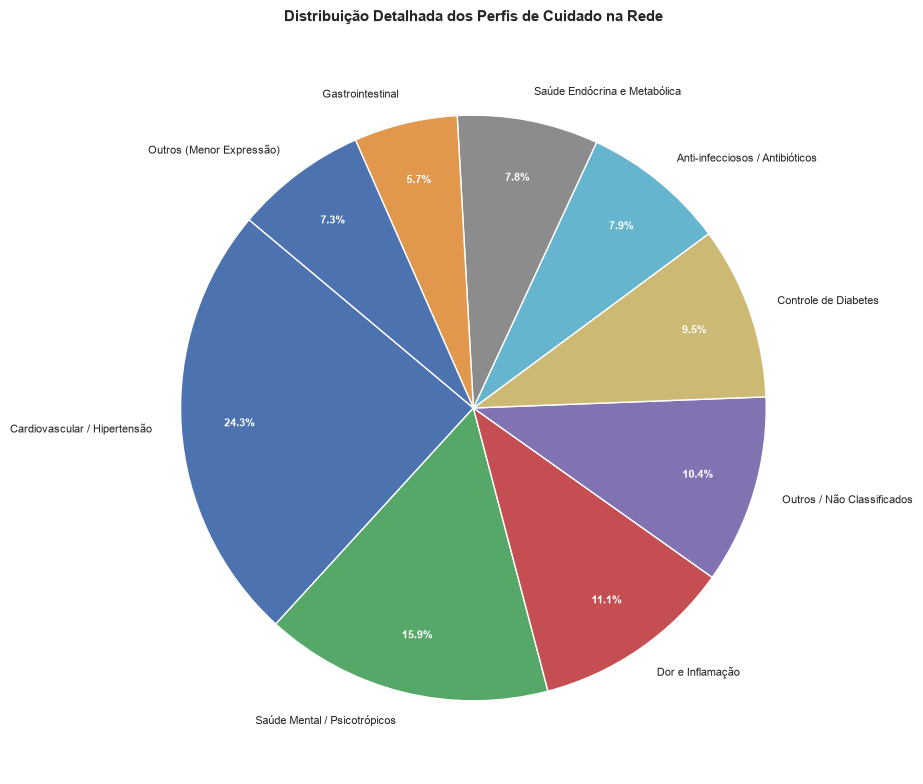

In [7]:
plt.figure(figsize=(9, 8))

contagem_pizza = df['perfil_cuidado'].value_counts()

n_principais = 8  
principais = contagem_pizza.iloc[:n_principais]
outros_soma = contagem_pizza.iloc[n_principais:].sum()

dados_finais = principais.copy()
if outros_soma > 0:
    dados_finais['Outros (Menor Expressão)'] = outros_soma

wedges, texts, autotexts = plt.pie(
    dados_finais, 
    labels=dados_finais.index, 
    autopct='%1.1f%%', 
    startangle=140,
    colors=cores[:len(dados_finais)],
    pctdistance=0.80
)

for text in texts:
    text.set_fontsize(8) 
for autotext in autotexts:
    autotext.set_fontsize(8)
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.title('Distribuição Detalhada dos Perfis de Cuidado na Rede', fontsize=11, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Distribuição Proporcional das Linhas de Cuidado
* **Predominância dos Grandes Eixos:** A visualização detalhada evidencia que o volume de dispensações na rede municipal concentra-se majoritariamente nos tratamentos para **Cardiovascular / Hipertensão (24,3%)** e **Saúde Mental / Psicotrópicos (15,9%)**, refletindo a alta carga de morbimortalidade dessas condições na atenção básica.
* **Diversificação da Demanda:** Categorias intermediárias como **Dor e Inflamação (11,1%)**, **Controle de Diabetes (9,5%)**, **Anti-infecciosos / Antibióticos (7,9%)** e **Saúde Endócrina e Metabólica (7,8%)** demonstram uma distribuição equilibrada do restante do suprimento farmacêutico.
* **Transparência Residual:** O grupo **"Outros / Não Classificados" (10,4%)** foi mantido isolado de forma explícita para assegurar a integridade da auditoria dos dados, representando insumos médico-hospitalares e dispensações pontuais que não compõem as linhas terapêuticas principais.

### 5. Os 10 Medicamentos Mais Dispensados no Total
Ranking geral dos princípios ativos ou produtos mais retirados pela população.

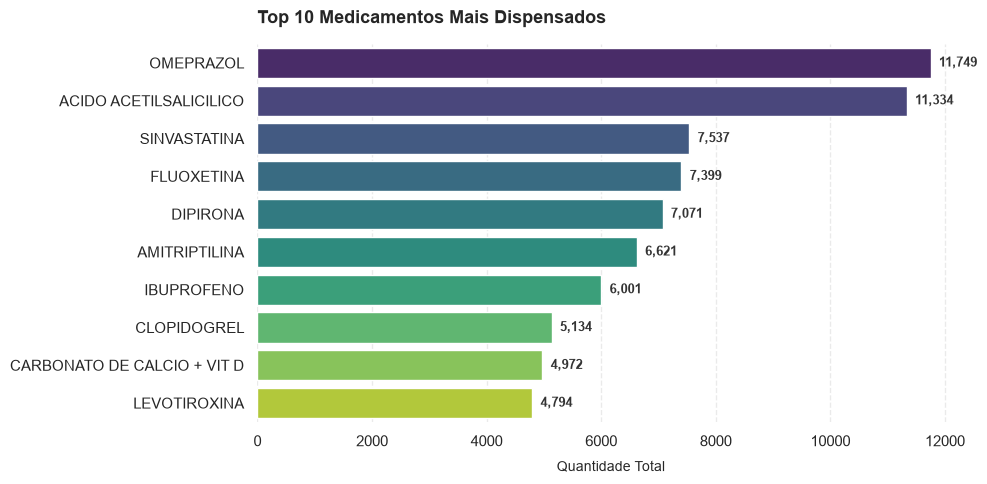

In [8]:
top_10_geral = df[coluna_med].value_counts().head(10).reset_index()
top_10_geral.columns = ['Medicamento', 'Quantidade']

top_10_geral['Medicamento'] = top_10_geral['Medicamento'].str.split('-').str[0].str.strip()

plt.figure(figsize=(10, 5), dpi=100)

ax = sns.barplot(
    data=top_10_geral,
    x='Quantidade',
    y='Medicamento',
    hue='Medicamento',
    palette='viridis',
    legend=False
)

sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.yaxis.grid(False)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f'{int(width):,}',
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(6, 0),
            textcoords='offset points',
            ha='left',
            va='center',
            fontsize=9,
            fontweight='bold',
            color='#333333'
        )

plt.title('Top 10 Medicamentos Mais Dispensados', fontsize=13, fontweight='bold', pad=15, loc='left')
plt.xlabel('Quantidade Total', fontsize=10, labelpad=8)
plt.ylabel('')
plt.tight_layout()
plt.show()

### Análise do Top 10 Medicamentos Mais Dispensados
O ranking geral evidencia a alta concentração de dispensações em fármacos de uso contínuo e prolongado voltados para doenças crônicas e distúrbios gástricos:
* **Destaques de Maior Demanda:** O **Omeprazol** (gastroprotetor) e o **Ácido Acetilsalicílico / AAS** (cardioprotetor/antiagregante) lideram o volume global de retiradas na rede municipal.
* **Perfil de Morbidadade:** A forte presença de medicamentos como **Sinvastatina**, **Fluoxetina**, **Amitriptilina** e **Levotiroxina** reforça que a assistência farmacêutica municipal é fortemente demandada pelo suporte a patologias crônicas (cardiovasculares, metabólicas e de saúde mental), exigindo um planejamento logístico robusto de abastecimento contínuo para evitar rupturas de estoque.

### 6. Análise por Período
Identificação de colunas de data para avaliar variações temporais.

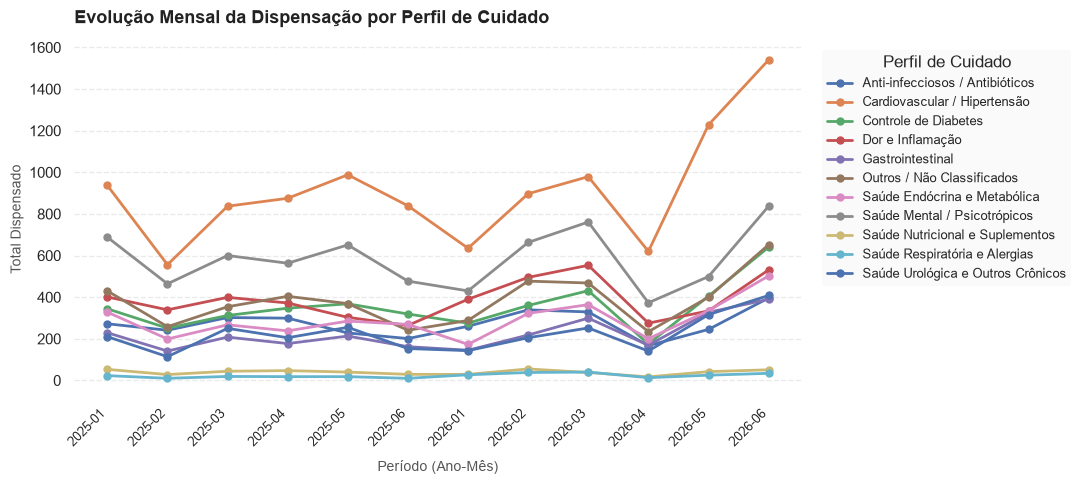

perfil_cuidado,Anti-infecciosos / Antibióticos,Cardiovascular / Hipertensão,Controle de Diabetes,Dor e Inflamação,Gastrointestinal,Outros / Não Classificados,Saúde Endócrina e Metabólica,Saúde Mental / Psicotrópicos,Saúde Nutricional e Suplementos,Saúde Respiratória e Alergias,Saúde Urológica e Outros Crônicos
periodo_mes,,,,,,,,,,,
2025-01,272,937,344,401,229,430,328,688,53,23,210
2025-02,241,556,251,339,141,258,199,464,28,10,114
2025-03,302,837,312,399,208,354,267,600,44,19,250
2025-04,299,875,347,372,177,404,238,563,47,18,205
2025-05,228,988,368,303,213,369,285,651,40,18,255
2025-06,201,839,319,264,162,241,269,477,29,10,153
2026-01,260,635,275,390,145,288,173,430,29,27,143
2026-02,339,897,360,495,218,477,322,663,55,38,205
2026-03,329,979,431,553,299,468,364,761,38,40,252


In [33]:
colunas_data = [col for col in df.columns if any(k in col.upper() for k in ['DATA', 'MES', 'ANO', 'PERIODO'])]

if 'perfil_cuidado' not in df.columns:
    print("Erro: A coluna 'perfil_cuidado' ainda não existe. Rode a célula de classificação dos medicamentos primeiro!")
elif colunas_data:
    col_data = colunas_data[0]
    
    df_tempo = df.copy()
    df_tempo[col_data] = pd.to_datetime(df_tempo[col_data], errors='coerce', dayfirst=True)
    df_tempo = df_tempo.dropna(subset=[col_data])
    
    df_tempo = df_tempo[df_tempo[col_data] <= pd.Timestamp.today()]
    
    df_tempo = df_tempo[df_tempo[col_data].dt.month <= 6]
    
    df_tempo['periodo_mes'] = df_tempo[col_data].dt.to_period('M')
    tabela_tempo = pd.crosstab(df_tempo['periodo_mes'], df_tempo['perfil_cuidado'])
    
    fig, ax = plt.subplots(figsize=(11, 5), dpi=100)
    
    for perfil in tabela_tempo.columns:
        ax.plot(
            tabela_tempo.index.astype(str), 
            tabela_tempo[perfil], 
            marker='o', 
            linewidth=2,
            markersize=5,
            label=perfil
        )
    
    sns.despine(left=True, bottom=True)
    ax.yaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
    ax.xaxis.grid(False)
    
    plt.title('Evolução Mensal da Dispensação por Perfil de Cuidado', fontsize=13, fontweight='bold', pad=15, loc='left', color='#222222')
    plt.xlabel('Período (Ano-Mês)', fontsize=10, labelpad=8, color='#555555')
    plt.ylabel('Total Dispensado', fontsize=10, color='#555555')
    plt.xticks(rotation=45, ha='right', fontsize=9)
    
    plt.legend(
        title='Perfil de Cuidado',
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        frameon=True,
        facecolor='#f9f9f9',
        edgecolor='none',
        fontsize=9
    )
    
    plt.tight_layout()
    plt.show()
    
    display(tabela_tempo)
else:
    print("Coluna de data não encontrada.")

### 7. Distribuição na Farmácia Básica Municipal
* **Modelo de Dispensação Centralizado:** A análise da coluna de estabelecimentos (`ups_nome`) revela que 100% dos 220.815 registros da base atual correspondem à **Farmácia Básica Municipal**. Isso evidencia que a rede municipal opera sob um modelo logístico centralizado, onde a farmácia central atua como o principal polo de suprimento e dispensação direta para a população do município.

In [32]:
print(f"Estabelecimento presente na base: {df['ups_nome'].iloc[0]} com {len(df):,} dispensações.")

Estabelecimento presente na base: FARMACIA BASICA MUNICIPAL com 220,815 dispensações.


# Síntese Geral dos Resultados e Indicadores da Rede Municipal

* **Concentração do Atendimento:** A análise integral de 220.815 registros evidencia que a rede municipal opera sob um modelo logístico centralizado na Farmácia Básica Municipal, servindo como o principal polo de suprimento e distribuição de insumos para o município.

* **Perfil de Demanda Terapêutica:** Os dados demonstram uma forte predominância de tratamentos voltados a doenças crônicas, com destaque absoluto para Cardiovascular / Hipertensão (24,3%) e Saúde Mental / Psicotrópicos (15,9%), evidenciando a principal carga de morbimortalidade atendida na rede pública.

* **Comportamento Sazonal e Temporal:** Os grandes eixos terapêuticos e categorias de menor porte (como Saúde Respiratória e Alergias) exibem variações mensais e picos pontuais ao longo de 2025 e 2026, sinalizando possíveis influências de sazonalidade climática e variações logísticas no abastecimento.

* **Transparência:** A manutenção explícita do grupo "Outros / Não Classificados" (10,4%) e das demais categorias residuais garante a integridade dos dados abertos, registrando insumos e dispensações de menor escala que fogem dos grandes protocolos padronizados.